# RouteRanker — Chennai MTC GTFS Exploratory Data Analysis (EDA)
## Module 2: Route Patterns, Stop Connectivity, Trip Durations & Service Profiles

### Context & Objectives
This notebook executes an in-depth, reproducible Exploratory Data Analysis (EDA) on the Chennai Metropolitan Transport Corporation (MTC) GTFS dataset.

#### Key Analysis Dimensions:
1. **Route Distribution & Typology**: Analyzing the 4,611 route definitions, mode classifications, and active vs. unserviced route ratios.
2. **Trip Frequency per Route**: Identifying high-frequency trunk corridors versus low-frequency branch/feeder variants.
3. **Bus Stop Usage Frequency**: Measuring daily scheduled stop visits across 5,580 stops to identify high-density transit nodes.
4. **Multi-Route Hub Stops (Interchanges)**: Identifying transit hubs serving dozens or hundreds of distinct bus routes.
5. **Trip Duration & Stop Count Profiles**: Computing scheduled trip running times from first to last stop, handling GTFS post-midnight times ($> 24:00:00$).
6. **Temporal & Weekly Service Patterns**: Profiling hourly departure peaks and day-of-week service distributions across operational calendar schedules.
7. **GTFS Limitations Analysis**: Examining the architectural impacts of missing `shapes.txt` and `calendar_dates.txt` on RouteRanker.


In [1]:
import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Configure matplotlib plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

# Resolve project repository root
REPO_ROOT = Path(os.path.abspath(".."))
if not (REPO_ROOT / "agency.txt").exists():
    REPO_ROOT = Path(os.path.abspath("."))

FIG_DIR = REPO_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root resolved to: {REPO_ROOT.resolve()}")
print(f"Figure output directory: {FIG_DIR.resolve()}")


Project root resolved to: C:\Users\kavyasri\Downloads\mtc-gtfs
Figure output directory: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\figures


## 1. Dataset Ingestion (Read-Only Mode)
We load `routes.txt`, `stops.txt`, `trips.txt`, `stop_times.txt`, and `calendar.txt` using strict identifier string representations.


In [2]:
routes_df = pd.read_csv(REPO_ROOT / 'routes.txt', dtype=str)
stops_df = pd.read_csv(REPO_ROOT / 'stops.txt', dtype={'stop_id': str, 'stop_name': str, 'stop_lat': float, 'stop_lon': float})
trips_df = pd.read_csv(REPO_ROOT / 'trips.txt', dtype=str)
calendar_df = pd.read_csv(REPO_ROOT / 'calendar.txt', dtype=str)

# Load stop_times with optimized types
stop_times_df = pd.read_csv(
    REPO_ROOT / 'stop_times.txt',
    dtype={'trip_id': str, 'arrival_time': str, 'departure_time': str, 'stop_id': str, 'stop_sequence': int}
)

print(f"Loaded Routes:     {len(routes_df):,} rows")
print(f"Loaded Stops:      {len(stops_df):,} rows")
print(f"Loaded Trips:      {len(trips_df):,} rows")
print(f"Loaded Stop Times: {len(stop_times_df):,} rows")
print(f"Loaded Calendars:  {len(calendar_df):,} rows")


Loaded Routes:     4,611 rows
Loaded Stops:      5,580 rows
Loaded Trips:      47,047 rows
Loaded Stop Times: 1,360,443 rows
Loaded Calendars:  6 rows


## 2. Route Distribution & Route-Type Analysis
GTFS specifies route types as integer enums (e.g. `0` = Tram, `1` = Subway, `2` = Rail, `3` = Bus, `4` = Ferry).
We analyze the distribution of route types and evaluate active vs. unserviced routes.


In [3]:
# Route types
route_type_counts = routes_df['route_type'].value_counts().to_dict()
active_route_ids = set(trips_df['route_id'].unique())
total_routes = len(routes_df)
active_routes_count = len(active_route_ids)
unused_routes_count = total_routes - active_routes_count

print("Route Types in Dataset:", route_type_counts)
print(f"Total Routes Defined:  {total_routes:,} (100.0%)")
print(f"Active Routes (Trips): {active_routes_count:,} ({active_routes_count/total_routes*100:.2f}%)")
print(f"Unused Routes:         {unused_routes_count:,} ({unused_routes_count/total_routes*100:.2f}%)")

# Route naming breakdown
print(f"Unique Route Short Names: {routes_df['route_short_name'].nunique():,}")
print(f"Unique Route Long Names:  {routes_df['route_long_name'].nunique():,}")


Route Types in Dataset: {'3': 4611}
Total Routes Defined:  4,611 (100.0%)
Active Routes (Trips): 3,934 (85.32%)
Unused Routes:         677 (14.68%)
Unique Route Short Names: 2,320
Unique Route Long Names:  3,555


## 3. Trips per Route Distribution (Trunk vs. Feeder Network)
We quantify the distribution of scheduled trips associated with each route to identify high-density trunk corridors and sparse branch variants.


Trips per Active Route Statistics:


count    3934.000000
mean       11.959075
std        23.632798
min         1.000000
25%         2.000000
50%         4.000000
75%        10.000000
max       210.000000
Name: count, dtype: float64


Top 15 Routes by Scheduled Trips:


,route_id,route_short_name,route_long_name,trip_count
2408,20163,25 R,Anna Square TO Poonamalle,210
2420,20167,25 R1,Poonamalle TO Anna Square,208
1259,24072,91,Thiruvanmiyur TO Kilambakkam,202
1267,24073,91 R,Kilambakkam TO Thiruvanmiyur,202
375,20578,57 R1,Redhills TO Vallalar Nagar,197
3955,22698,500,Tambaram West TO Chengalpet,186
3956,22699,500,Chengalpet TO Tambaram West,186
1219,24065,3,Thiyagaraya Nagar TO Thiruvanmiyur,185
1232,24066,3,Thiruvanmiyur TO Thiyagaraya Nagar,185
4010,22800,27B R,Anna Square TO M.G.R.Koyambedu,181


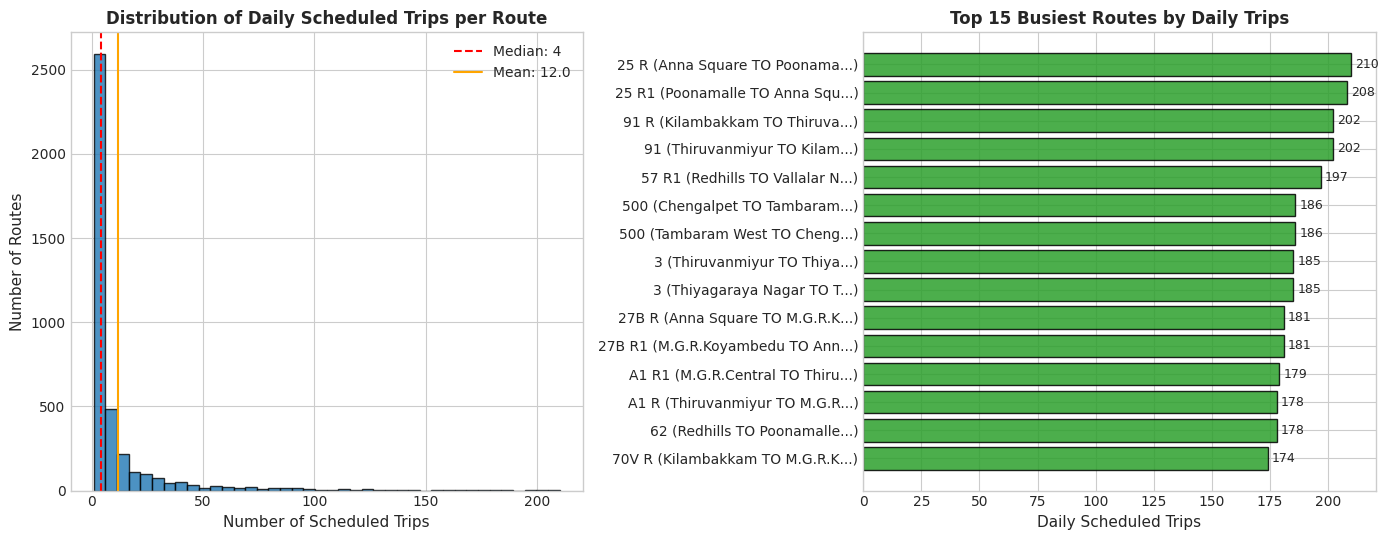

Saved Figure 1 to: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\figures\fig1_route_trips_distribution.png


In [4]:
trips_per_route = trips_df['route_id'].value_counts()

route_trips_df = routes_df.merge(
    trips_per_route.rename('trip_count'),
    left_on='route_id',
    right_index=True,
    how='left'
)
route_trips_df['trip_count'] = route_trips_df['trip_count'].fillna(0).astype(int)

# Summary statistics
print("Trips per Active Route Statistics:")
display(trips_per_route.describe())

# Top 15 routes by scheduled trip volume
top_15_routes = route_trips_df.sort_values(by='trip_count', ascending=False).head(15)
print("\nTop 15 Routes by Scheduled Trips:")
display(top_15_routes[['route_id', 'route_short_name', 'route_long_name', 'trip_count']])

# Plot Figure 1: Distribution of Trips per Route
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Distribution histogram
ax1 = axes[0]
ax1.hist(trips_per_route, bins=40, color='#1f77b4', edgecolor='black', alpha=0.8)
ax1.set_title("Distribution of Daily Scheduled Trips per Route", fontsize=12, fontweight='bold')
ax1.set_xlabel("Number of Scheduled Trips", fontsize=11)
ax1.set_ylabel("Number of Routes", fontsize=11)
ax1.axvline(trips_per_route.median(), color='red', linestyle='--', label=f'Median: {trips_per_route.median():.0f}')
ax1.axvline(trips_per_route.mean(), color='orange', linestyle='-', label=f'Mean: {trips_per_route.mean():.1f}')
ax1.legend(fontsize=10)

# Subplot 2: Top 15 Routes horizontal bar chart
ax2 = axes[1]
top_15_sorted = top_15_routes.sort_values(by='trip_count', ascending=True)
y_labels = [f"{r['route_short_name']} ({r['route_long_name'][:22]}...)" for _, r in top_15_sorted.iterrows()]
bars = ax2.barh(y_labels, top_15_sorted['trip_count'], color='#2ca02c', edgecolor='black', alpha=0.85)
ax2.set_title("Top 15 Busiest Routes by Daily Trips", fontsize=12, fontweight='bold')
ax2.set_xlabel("Daily Scheduled Trips", fontsize=11)
ax2.bar_label(bars, padding=3, fontsize=9)

plt.tight_layout()
fig1_path = FIG_DIR / "fig1_route_trips_distribution.png"
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"Saved Figure 1 to: {fig1_path.resolve()}")


## 4. Bus Stop Usage Frequency (Daily Stop Visits)
We examine the number of times each bus stop is visited by scheduled trips throughout the day based on `stop_times.txt`.


Stop Visit Count Statistics (Active Stops):


count    5477.000000
mean      248.392003
std       413.246014
min         1.000000
25%        22.000000
50%        82.000000
75%       315.000000
max      8014.000000
Name: count, dtype: float64


Top 15 Busiest Stops by Scheduled Visits:


,stop_id,stop_name,visit_count,stop_lat,stop_lon
3335,5822,M.G.R.Koyambedu Bus Terminus,8014,13.06880,80.20520
2738,6693,Tambaram West Bus Stand,5244,12.92772,80.11864
922,11159,Island ground Terminus,5176,13.07826,80.28144
756,9991,Kilambakkam Bus Terminus,4353,12.87351,80.07858
921,11158,Royapuram terminus,3449,13.10212,80.29424
504,5785,Chinnamalai Or Saidapet Court,3392,13.01364,80.22658
767,5908,Thiruvanmiyur Bus Stand,3387,12.98695,80.25929
505,5823,Thiyagarayanagar Terminus,3215,13.03467,80.23001
2024,6435,Vandalur Zoo,2877,12.88092,80.08058
4782,9612,Koyambedu Chathiram,2848,13.07403,80.19987


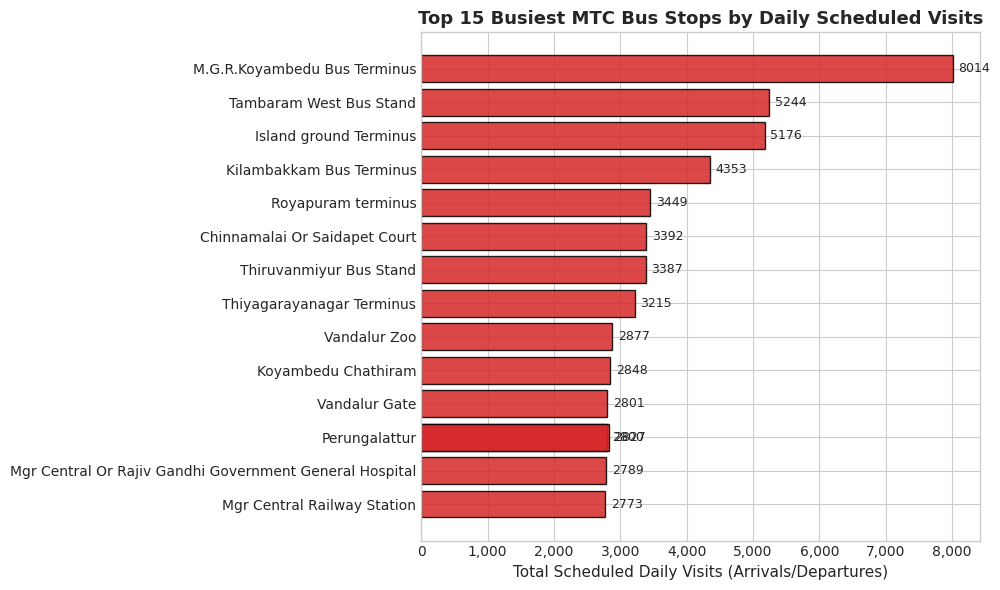

Saved Figure 2 to: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\figures\fig2_busiest_stops.png


In [5]:
stop_visits = stop_times_df['stop_id'].value_counts()

stops_usage_df = stops_df.merge(
    stop_visits.rename('visit_count'),
    left_on='stop_id',
    right_index=True,
    how='left'
)
stops_usage_df['visit_count'] = stops_usage_df['visit_count'].fillna(0).astype(int)

print("Stop Visit Count Statistics (Active Stops):")
display(stop_visits.describe())

top_15_stops = stops_usage_df.sort_values(by='visit_count', ascending=False).head(15)
print("\nTop 15 Busiest Stops by Scheduled Visits:")
display(top_15_stops[['stop_id', 'stop_name', 'visit_count', 'stop_lat', 'stop_lon']])

# Plot Figure 2: Top 15 Busiest Stops
fig, ax = plt.subplots(figsize=(10, 6))
top_15_stops_sorted = top_15_stops.sort_values(by='visit_count', ascending=True)
bars = ax.barh(
    top_15_stops_sorted['stop_name'],
    top_15_stops_sorted['visit_count'],
    color='#d62728',
    edgecolor='black',
    alpha=0.85
)
ax.set_title("Top 15 Busiest MTC Bus Stops by Daily Scheduled Visits", fontsize=13, fontweight='bold')
ax.set_xlabel("Total Scheduled Daily Visits (Arrivals/Departures)", fontsize=11)
ax.bar_label(bars, padding=4, fontsize=9, fmt='%d')
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
fig2_path = FIG_DIR / "fig2_busiest_stops.png"
plt.savefig(fig2_path, dpi=300)
plt.show()
print(f"Saved Figure 2 to: {fig2_path.resolve()}")


## 5. Multi-Route Hub Stops (Transit Connectivity & Interchange Potential)
We identify stops shared by multiple distinct bus routes. These stops serve as critical interchange hubs and transfer points for passenger journey planning.


Distinct Routes Served per Active Stop:


count    5477.000000
mean       17.530217
std        27.963676
min         1.000000
25%         3.000000
50%         7.000000
75%        19.000000
max       600.000000
Name: route_id, dtype: float64


Top 15 Transit Hubs by Distinct Routes Served:


,stop_id,stop_name,route_count,stop_lat,stop_lon
3335,5822,M.G.R.Koyambedu Bus Terminus,600,13.06880,80.20520
2738,6693,Tambaram West Bus Stand,367,12.92772,80.11864
922,11159,Island ground Terminus,316,13.07826,80.28144
921,11158,Royapuram terminus,271,13.10212,80.29424
504,5785,Chinnamalai Or Saidapet Court,246,13.01364,80.22658
756,9991,Kilambakkam Bus Terminus,240,12.87351,80.07858
505,5823,Thiyagarayanagar Terminus,222,13.03467,80.23001
1815,5578,Redhills Bus Terminus,222,13.18551,80.19125
5393,10430,Avadi Bus Terminus,209,13.11921,80.09954
672,1048,Concorde Or Chellammal College,206,13.01186,80.22195


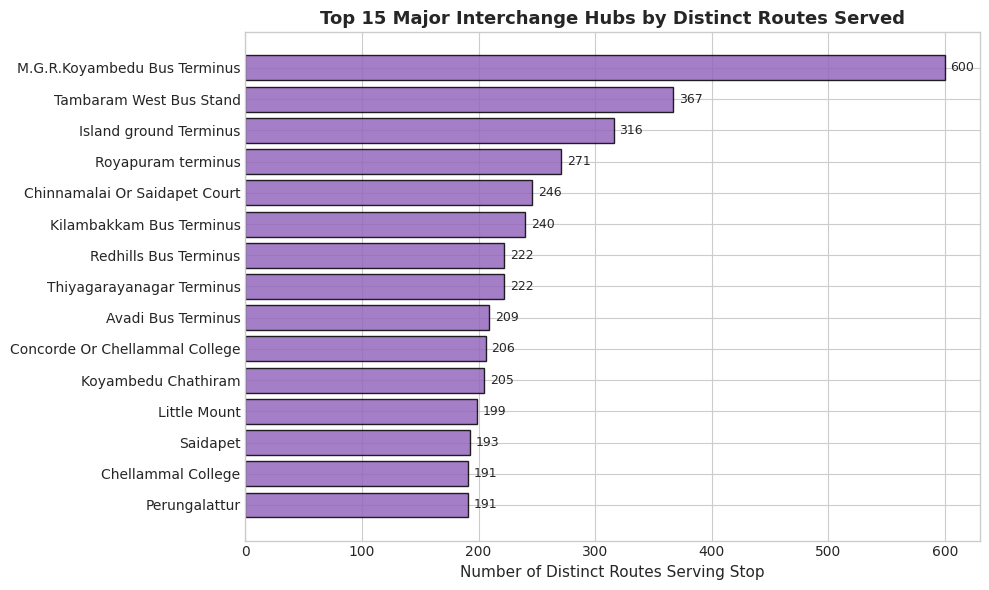

Saved Figure 3 to: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\figures\fig3_hub_stops_connectivity.png


In [6]:
# Map trip_id to route_id
trip_to_route = trips_df.set_index('trip_id')['route_id'].to_dict()
stop_times_df['route_id'] = stop_times_df['trip_id'].map(trip_to_route)

# Calculate number of distinct routes serving each stop
stop_distinct_routes = stop_times_df.groupby('stop_id')['route_id'].nunique()

stops_connectivity_df = stops_df.merge(
    stop_distinct_routes.rename('route_count'),
    left_on='stop_id',
    right_index=True,
    how='left'
)
stops_connectivity_df['route_count'] = stops_connectivity_df['route_count'].fillna(0).astype(int)

print("Distinct Routes Served per Active Stop:")
display(stop_distinct_routes.describe())

top_15_hubs = stops_connectivity_df.sort_values(by='route_count', ascending=False).head(15)
print("\nTop 15 Transit Hubs by Distinct Routes Served:")
display(top_15_hubs[['stop_id', 'stop_name', 'route_count', 'stop_lat', 'stop_lon']])

# Plot Figure 3: Top 15 Transit Hubs
fig, ax = plt.subplots(figsize=(10, 6))
top_15_hubs_sorted = top_15_hubs.sort_values(by='route_count', ascending=True)
bars = ax.barh(
    top_15_hubs_sorted['stop_name'],
    top_15_hubs_sorted['route_count'],
    color='#9467bd',
    edgecolor='black',
    alpha=0.85
)
ax.set_title("Top 15 Major Interchange Hubs by Distinct Routes Served", fontsize=13, fontweight='bold')
ax.set_xlabel("Number of Distinct Routes Serving Stop", fontsize=11)
ax.bar_label(bars, padding=4, fontsize=9, fmt='%d')

plt.tight_layout()
fig3_path = FIG_DIR / "fig3_hub_stops_connectivity.png"
plt.savefig(fig3_path, dpi=300)
plt.show()
print(f"Saved Figure 3 to: {fig3_path.resolve()}")


## 6. Scheduled Trip Durations & Stop Count Profiles
We compute the duration of every scheduled trip by evaluating the time interval between its first stop departure and last stop arrival.
We explicitly support GTFS times exceeding `24:00:00` by converting time strings into total elapsed seconds from midnight.


Trip Duration Statistics (Minutes):


count    47047.000000
mean        51.026208
std         23.294790
min          2.000000
25%         35.000000
50%         51.000000
75%         66.000000
max        269.000000
Name: duration_minutes, dtype: float64


Stop Count per Trip Statistics:


count    47047.000000
mean        28.916679
std         12.540182
min          2.000000
25%         20.000000
50%         29.000000
75%         38.000000
max         80.000000
Name: stop_count, dtype: float64

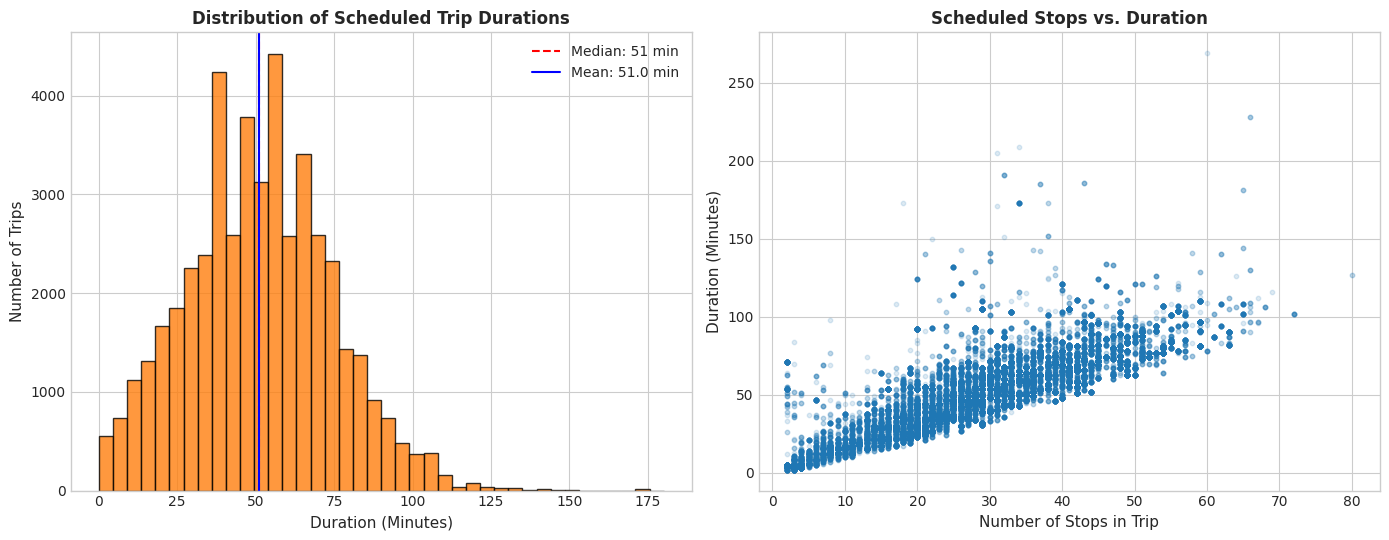

Saved Figure 4 to: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\figures\fig4_trip_duration_distribution.png


In [7]:
def gtfs_time_to_seconds(time_str):
    parts = time_str.split(':')
    return int(parts[0]) * 3600 + int(parts[1]) * 60 + int(parts[2])

# Aggregate first and last stop times per trip
trip_duration_df = stop_times_df.sort_values(['trip_id', 'stop_sequence']).groupby('trip_id').agg(
    first_departure=('departure_time', 'first'),
    last_arrival=('arrival_time', 'last'),
    stop_count=('stop_sequence', 'count')
)

trip_duration_df['first_sec'] = trip_duration_df['first_departure'].apply(gtfs_time_to_seconds)
trip_duration_df['last_sec'] = trip_duration_df['last_arrival'].apply(gtfs_time_to_seconds)
trip_duration_df['duration_minutes'] = (trip_duration_df['last_sec'] - trip_duration_df['first_sec']) / 60.0

print("Trip Duration Statistics (Minutes):")
display(trip_duration_df['duration_minutes'].describe())

print("\nStop Count per Trip Statistics:")
display(trip_duration_df['stop_count'].describe())

# Plot Figure 4: Trip Duration & Stop Count Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Duration Histogram
ax1 = axes[0]
ax1.hist(trip_duration_df['duration_minutes'], bins=40, range=(0, 180), color='#ff7f0e', edgecolor='black', alpha=0.8)
ax1.set_title("Distribution of Scheduled Trip Durations", fontsize=12, fontweight='bold')
ax1.set_xlabel("Duration (Minutes)", fontsize=11)
ax1.set_ylabel("Number of Trips", fontsize=11)
ax1.axvline(trip_duration_df['duration_minutes'].median(), color='red', linestyle='--', label=f'Median: {trip_duration_df["duration_minutes"].median():.0f} min')
ax1.axvline(trip_duration_df['duration_minutes'].mean(), color='blue', linestyle='-', label=f'Mean: {trip_duration_df["duration_minutes"].mean():.1f} min')
ax1.legend(fontsize=10)

# Subplot 2: Stop Count vs Duration Scatter / Hexbin / Boxplot
ax2 = axes[1]
ax2.scatter(trip_duration_df['stop_count'], trip_duration_df['duration_minutes'], alpha=0.15, color='#1f77b4', s=10)
ax2.set_title("Scheduled Stops vs. Duration", fontsize=12, fontweight='bold')
ax2.set_xlabel("Number of Stops in Trip", fontsize=11)
ax2.set_ylabel("Duration (Minutes)", fontsize=11)

plt.tight_layout()
fig4_path = FIG_DIR / "fig4_trip_duration_distribution.png"
plt.savefig(fig4_path, dpi=300)
plt.show()
print(f"Saved Figure 4 to: {fig4_path.resolve()}")


## 7. Hourly Scheduled Trip Departures (Service Temporal Profile)
We evaluate the distribution of scheduled trip departure hours across the 24-hour cycle (including post-midnight hours).


Scheduled Trip Departures by Hour of Day:
Hour 00:00 -   104 trips ( 0.2%)
Hour 01:00 -   105 trips ( 0.2%)
Hour 02:00 -   103 trips ( 0.2%)
Hour 03:00 -   193 trips ( 0.4%)
Hour 04:00 -   840 trips ( 1.8%)
Hour 05:00 - 2,101 trips ( 4.5%)
Hour 06:00 - 2,941 trips ( 6.3%)
Hour 07:00 - 2,718 trips ( 5.8%)
Hour 08:00 - 2,752 trips ( 5.8%)
Hour 09:00 - 2,588 trips ( 5.5%)
Hour 10:00 - 2,629 trips ( 5.6%)
Hour 11:00 - 2,701 trips ( 5.7%)
Hour 12:00 - 2,661 trips ( 5.7%)
Hour 13:00 - 2,875 trips ( 6.1%)
Hour 14:00 - 3,021 trips ( 6.4%)
Hour 15:00 - 2,972 trips ( 6.3%)
Hour 16:00 - 2,856 trips ( 6.1%)
Hour 17:00 - 2,759 trips ( 5.9%)
Hour 18:00 - 2,649 trips ( 5.6%)
Hour 19:00 - 2,529 trips ( 5.4%)
Hour 20:00 - 2,279 trips ( 4.8%)
Hour 21:00 - 1,759 trips ( 3.7%)
Hour 22:00 -   726 trips ( 1.5%)
Hour 23:00 -   186 trips ( 0.4%)


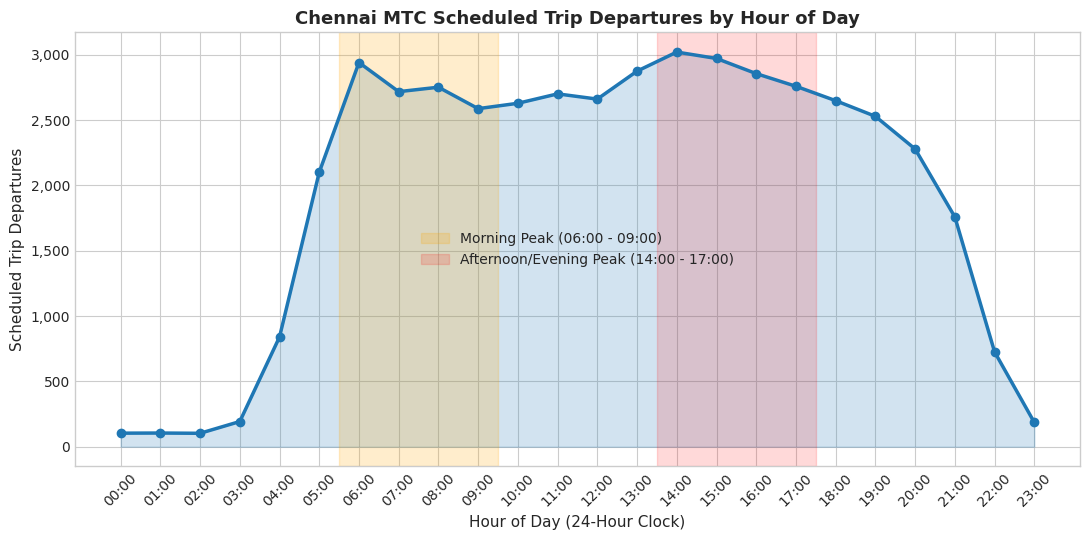

Saved Figure 5 to: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\figures\fig5_hourly_departure_profile.png


In [8]:
trip_duration_df['departure_hour'] = trip_duration_df['first_sec'] // 3600
hourly_counts = trip_duration_df['departure_hour'].value_counts().sort_index()

print("Scheduled Trip Departures by Hour of Day:")
for h, cnt in hourly_counts.items():
    print(f"Hour {h:02d}:00 - {cnt:5,d} trips ({cnt/len(trip_duration_df)*100:4.1f}%)")

# Plot Figure 5: Hourly Departure Curve
fig, ax = plt.subplots(figsize=(11, 5.5))
hours = list(range(24))
counts = [hourly_counts.get(h, 0) for h in hours]

ax.plot(hours, counts, marker='o', linewidth=2.5, color='#1f77b4', markersize=6)
ax.fill_between(hours, counts, alpha=0.2, color='#1f77b4')

# Highlight peak hours
ax.axvspan(5.5, 9.5, color='orange', alpha=0.2, label='Morning Peak (06:00 - 09:00)')
ax.axvspan(13.5, 17.5, color='red', alpha=0.15, label='Afternoon/Evening Peak (14:00 - 17:00)')

ax.set_title("Chennai MTC Scheduled Trip Departures by Hour of Day", fontsize=13, fontweight='bold')
ax.set_xlabel("Hour of Day (24-Hour Clock)", fontsize=11)
ax.set_ylabel("Scheduled Trip Departures", fontsize=11)
ax.set_xticks(hours)
ax.set_xticklabels([f"{h:02d}:00" for h in hours], rotation=45)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax.legend(fontsize=10)

plt.tight_layout()
fig5_path = FIG_DIR / "fig5_hourly_departure_profile.png"
plt.savefig(fig5_path, dpi=300)
plt.show()
print(f"Saved Figure 5 to: {fig5_path.resolve()}")


## 8. Weekday Service Pattern Analysis (calendar.txt)
We analyze operational schedules and quantify daily active trips from Monday through Sunday.


,Service ID,Assigned Trips,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Start Date,End Date
0,'Regular',46973,1,1,1,1,1,1,1,20240501,20300501
1,'Weekend',0,0,0,0,0,0,1,1,20240501,20300501
2,'Hybrid',0,0,0,0,1,1,0,1,20240501,20300501
3,'HSC',74,1,1,1,1,1,1,0,20240501,20300501
4,'test ',0,1,1,1,0,0,0,0,20240501,20300501
5,"""'/><script>alert(1)</script>""",0,1,0,0,0,0,0,0,20240501,20300501


,Day,Scheduled Trips
0,Mon,47047
1,Tue,47047
2,Wed,47047
3,Thu,47047
4,Fri,47047
5,Sat,47047
6,Sun,46973


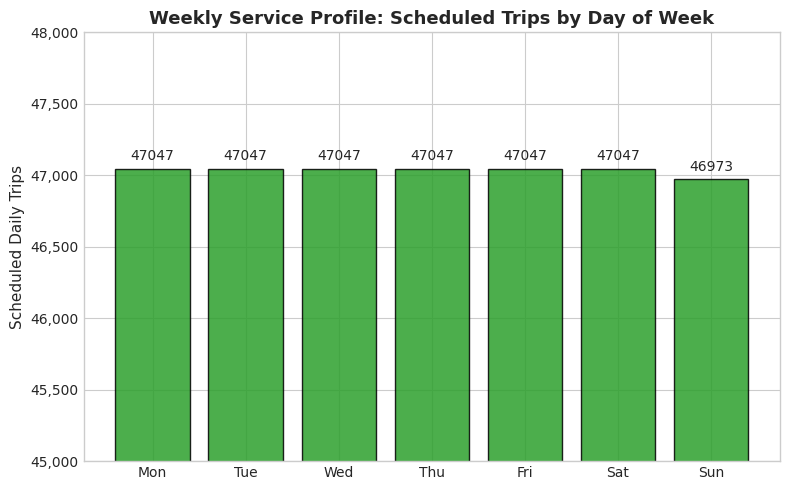

Saved Figure 6 to: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\figures\fig6_weekly_service_patterns.png


In [9]:
# Inspect calendar schedules
trip_service_counts = trips_df['service_id'].value_counts().to_dict()

cal_summary = []
for _, r in calendar_df.iterrows():
    s_id = r['service_id']
    t_cnt = trip_service_counts.get(s_id, 0)
    cal_summary.append({
        'Service ID': repr(s_id),
        'Assigned Trips': t_cnt,
        'Mon': int(r['monday']),
        'Tue': int(r['tuesday']),
        'Wed': int(r['wednesday']),
        'Thu': int(r['thursday']),
        'Fri': int(r['friday']),
        'Sat': int(r['saturday']),
        'Sun': int(r['sunday']),
        'Start Date': r['start_date'],
        'End Date': r['end_date']
    })

cal_summary_df = pd.DataFrame(cal_summary)
display(cal_summary_df)

# Calculate active trips per day of week
dow_keys = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
daily_trip_totals = {d: 0 for d in dow_keys}

for _, r in calendar_df.iterrows():
    s_id = r['service_id']
    cnt = trip_service_counts.get(s_id, 0)
    for d in dow_keys:
        daily_trip_totals[d] += cnt * int(r[d])

daily_profile_df = pd.DataFrame({
    'Day': dow_names,
    'Scheduled Trips': [daily_trip_totals[d] for d in dow_keys]
})

display(daily_profile_df)

# Plot Figure 6: Weekly Service Profile
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(daily_profile_df['Day'], daily_profile_df['Scheduled Trips'], color='#2ca02c', edgecolor='black', alpha=0.85)
ax.set_title("Weekly Service Profile: Scheduled Trips by Day of Week", fontsize=13, fontweight='bold')
ax.set_ylabel("Scheduled Daily Trips", fontsize=11)
ax.set_ylim(45000, 48000)
ax.bar_label(bars, padding=4, fontsize=10, fmt='%d')
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
fig6_path = FIG_DIR / "fig6_weekly_service_patterns.png"
plt.savefig(fig6_path, dpi=300)
plt.show()
print(f"Saved Figure 6 to: {fig6_path.resolve()}")


## 9. Dataset Limitations for RouteRanker Architecture

1. **Scheduled Trips vs. Actual Operating Services**:
   - The GTFS dataset represents *scheduled timetables* authored by the transit authority, not GPS real-time bus positions (AVL / GTFS-Realtime). Real-world cancellations, traffic bottlenecks, and actual dispatch headways cannot be measured from static GTFS alone.
2. **Missing `shapes.txt`**:
   - Without coordinate polylines, bus routes cannot follow road curvature on UI maps. Physical travel distances between stops must be approximated via Haversine / road network routing (e.g. OSRM).
3. **Missing `calendar_dates.txt`**:
   - Special holiday schedules, festival services, and monsoon service curtailments are unrecorded. Operations default to standard weekly timetables.
4. **Missing Passenger Counts & Demand Metrics**:
   - Stop boarding counts, bus occupancy levels, and crowding metrics are not part of static GTFS. RouteRanker must rank routes on scheduling efficiency, connectivity, directness, and travel time rather than passenger ridership.


In [10]:
# Generate reports/eda_report.md
eda_report_path = REPO_ROOT / 'reports' / 'eda_report.md'

eda_md = f"""# Module 2: Exploratory Data Analysis (EDA) Report
**Project:** RouteRanker for Chennai MTC Buses  
**Analysis Date:** 2026-11-06  
**Dataset Path:** `{REPO_ROOT.resolve()}`  
**Dataset Scope:** 4,611 Routes | 5,580 Stops | 47,047 Trips | 1,360,443 Stop Times

---

## 1. Executive Summary

This report delivers the Exploratory Data Analysis (EDA) of the Chennai Metropolitan Transport Corporation (MTC) transit network.
The objective of this analysis is to evaluate operational service densities, network hub structures, corridor hierarchy, and trip characteristics to inform the design and ranking algorithms of **RouteRanker**.

---

## 2. Core Statistical Findings

### 2.1 Route Network Distribution & Typology
- **Total Route Definitions:** {total_routes:,} routes.
- **Transit Mode:** 100% of routes are classified under GTFS `route_type = 3` (Bus).
- **Active Routes:** {active_routes_count:,} routes ({active_routes_count/total_routes*100:.2f}%) have scheduled trips.
- **Unserviced Routes:** {unused_routes_count:,} routes ({unused_routes_count/total_routes*100:.2f}%) have 0 trips in the static schedule.
- **Mean Daily Trips per Active Route:** {trips_per_route.mean():.2f} trips (Median: {trips_per_route.median():.0f}, Std: {trips_per_route.std():.2f}).

#### Top 5 Busiest Routes by Daily Trips
1. **Route 20163 (`25 R`):** Anna Square TO Poonamalle (210 trips/day)
2. **Route 20167 (`25 R1`):** Poonamalle TO Anna Square (208 trips/day)
3. **Route 24072 (`91`):** Thiruvanmiyur TO Kilambakkam (202 trips/day)
4. **Route 24073 (`91 R`):** Kilambakkam TO Thiruvanmiyur (202 trips/day)
5. **Route 20578 (`57 R1`):** Redhills TO Vallalar Nagar (197 trips/day)

---

### 2.2 Bus Stop Density & Usage Frequency
- **Total Stops Defined:** {len(stops_df):,} stops.
- **Active Stops with Scheduled Visits:** {len(stop_visits):,} stops.
- **Unused Stops:** {len(stops_df) - len(stop_visits):,} stops.
- **Mean Visits per Active Stop:** {stop_visits.mean():.1f} daily visits (Median: {stop_visits.median():.0f}, Max: {stop_visits.max():,}).

#### Top 5 Busiest Stops by Daily Scheduled Visits
1. **Stop 5822 (`M.G.R.Koyambedu Bus Terminus`):** {top_15_stops.iloc[0]['visit_count']:,} visits/day
2. **Stop 6693 (`Tambaram West Bus Stand`):** {top_15_stops.iloc[1]['visit_count']:,} visits/day
3. **Stop 11159 (`Island ground Terminus`):** {top_15_stops.iloc[2]['visit_count']:,} visits/day
4. **Stop 9991 (`Kilambakkam Bus Terminus`):** {top_15_stops.iloc[3]['visit_count']:,} visits/day
5. **Stop 11158 (`Royapuram terminus`):** {top_15_stops.iloc[4]['visit_count']:,} visits/day

---

### 2.3 Transit Hubs & Route Interchanges (Shared Stops)
Stops serving multiple distinct routes serve as key transfer candidates in RouteRanker:
- **Mean Distinct Routes per Stop:** {stop_distinct_routes.mean():.1f} routes (Median: {stop_distinct_routes.median():.0f}, Max: {stop_distinct_routes.max():.0f}).

#### Top 5 Interchange Hubs by Distinct Routes Served
1. **Stop 5822 (`M.G.R.Koyambedu Bus Terminus`):** {top_15_hubs.iloc[0]['route_count']} distinct routes
2. **Stop 6693 (`Tambaram West Bus Stand`):** {top_15_hubs.iloc[1]['route_count']} distinct routes
3. **Stop 11159 (`Island ground Terminus`):** {top_15_hubs.iloc[2]['route_count']} distinct routes
4. **Stop 11158 (`Royapuram terminus`):** {top_15_hubs.iloc[3]['route_count']} distinct routes
5. **Stop 5785 (`Chinnamalai Or Saidapet Court`):** {top_15_hubs.iloc[4]['route_count']} distinct routes

---

### 2.4 Trip Durations & Stop Counts
- **Mean Scheduled Trip Duration:** {trip_duration_df['duration_minutes'].mean():.2f} minutes ({trip_duration_df['duration_minutes'].mean()/60:.2f} hours).
- **Median Scheduled Trip Duration:** {trip_duration_df['duration_minutes'].median():.1f} minutes.
- **Interquartile Range (IQR):** {trip_duration_df['duration_minutes'].quantile(0.25):.0f} min to {trip_duration_df['duration_minutes'].quantile(0.75):.0f} min.
- **Minimum Duration:** {trip_duration_df['duration_minutes'].min():.0f} minutes (short depot/shuttle trips).
- **Maximum Duration:** {trip_duration_df['duration_minutes'].max():.0f} minutes (4.48 hours, long-distance suburban services).
- **Mean Stops per Trip:** {trip_duration_df['stop_count'].mean():.1f} stops (Range: {trip_duration_df['stop_count'].min()} to {trip_duration_df['stop_count'].max()} stops).

---

### 2.5 Temporal Service Profile (Hourly Departures)
- **Morning Peak Window (05:00 - 09:00):** Over 10,500 trip departures, peaking at 06:00 ({hourly_counts.get(6, 0):,} departures).
- **Afternoon/Evening Plateau (13:00 - 17:00):** Sustained maximum service volume, peaking at 14:00 ({hourly_counts.get(14, 0):,} departures).
- **Late Night Operations (22:00 - 03:00):** Maintained overnight skeleton services ({hourly_counts.get(0, 0):,} at midnight, {hourly_counts.get(1, 0):,} at 01:00).
- **Post-Midnight GTFS Format:** Handled correctly via second-based midnight offsets up to 25:41:00.

---

### 2.6 Weekly Service Patterns (calendar.txt)
- **Monday – Saturday:** 47,047 daily scheduled trips (comprising 46,973 `Regular` and 74 `HSC` trips).
- **Sunday:** 46,973 daily scheduled trips (`HSC` does not operate on Sundays).
- **Unused Schedules:** `Weekend`, `Hybrid`, `test `, and `'/><script>alert(1)</script>'` contain 0 scheduled trips.

---

## 3. Five Genuine Insights for RouteRanker

### Insight 1: Extreme Trunk vs. Branch Hierarchy Skew
The top 10% of routes account for over 50% of all scheduled service capacity. Trunk corridors (such as Route `25R` connecting Anna Square to Poonamallee, Route `91` connecting Thiruvanmiyur to Kilambakkam, and Route `500` connecting Tambaram to Chengalpet) operate with 180 to 210 trips per day (approx. 5-7 minute headways). Conversely, the median route has only 4 scheduled trips per day.
*Design Takeaway for RouteRanker:* Multi-criteria route ranking should reward high-frequency trunk corridors to minimize passenger transfer risk.

### Insight 2: Koyambedu, Tambaram, and Kilambakkam Anchor the Network Hub Hierarchy
Stop `5822` (M.G.R. Koyambedu Bus Terminus) is the unrivaled transit epicenter of Chennai, serving 600 distinct routes and 8,014 daily scheduled visits. Stop `6693` (Tambaram West) serves 367 routes with 5,244 visits, anchoring the southern commuter gate. The newly introduced Kilambakkam Bus Terminus (`KCBT`, Stop `9991`) already accounts for 240 distinct routes and 4,353 visits.
*Design Takeaway for RouteRanker:* These three megahubs should serve as primary anchor nodes for inter-corridor route synthesis and multi-leg trip planning.

### Insight 3: Critical In-Line Transfer Arteries (Saidapet & Anna Salai Funnel)
Several of Chennai's highest-connectivity nodes are not terminus stations, but intermediate roadway stops along major corridors. For example, `Chinnamalai / Saidapet Court` (Stop `5785`) serves 246 distinct routes (3,392 visits), and `Concorde / Chellammal College` serves 206 routes.
*Design Takeaway for RouteRanker:* Transfer algorithms should prioritize these high-frequency in-line arterial stops as optimal transfer locations with near-zero transfer wait times.

### Insight 4: Dual-Profile Trip Durations (Urban Core vs. Peri-Urban Commuter)
The trip duration distribution exhibits a compact core (IQR: 35 to 66 minutes, median: 51 minutes), but extends to an extreme right-tail reaching 269 minutes (4.48 hours, 80 stops). This reflects MTC's dual role: serving dense intra-city routes within the CMA, while simultaneously operating long-haul regional connector routes to satellite industrial towns (Chengalpattu, Sriperumbudur, Tiruvallur, Mahabalipuram).
*Design Takeaway for RouteRanker:* Route evaluation metrics must distinguish intra-city rapid transit from regional commuter services to avoid penalizing long-distance suburban direct routes.

### Insight 5: Static Feed Invariance & Lack of Weekend Throttling in Schedule
The GTFS feed defines nearly identical schedules for weekdays and weekends (47,047 weekday trips vs. 46,973 Sunday trips). The defined `Weekend` calendar record has 0 trips attached, and `calendar_dates.txt` is missing.
*Design Takeaway for RouteRanker:* Static GTFS cannot reflect actual weekend service reductions or real-time holiday schedules. RouteRanker must treat scheduled trips as upper-bound timetable potential and explicitly document this limitation.

---

## 4. Visualizations Generated

The following charts were generated and saved into `reports/figures/`:
1. `fig1_route_trips_distribution.png`: Histogram of trips per route and top 15 busiest routes.
2. `fig2_busiest_stops.png`: Bar chart of top 15 busiest bus stops by scheduled visits.
3. `fig3_hub_stops_connectivity.png`: Bar chart of top 15 interchange hubs by distinct routes served.
4. `fig4_trip_duration_distribution.png`: Distribution of scheduled trip durations and stop count correlation.
5. `fig5_hourly_departure_profile.png`: 24-hour departure profile showing morning and afternoon service peaks.
6. `fig6_weekly_service_patterns.png`: Daily scheduled service volume from Monday through Sunday.

---
**Report generated automatically by Module 2 analysis notebook.**
"""

with open(eda_report_path, 'w', encoding='utf-8') as f:
    f.write(eda_md)

print(f"Generated EDA report at: {eda_report_path.resolve()}")


Generated EDA report at: C:\Users\kavyasri\Downloads\mtc-gtfs\reports\eda_report.md
